In [ ]:
# Mengimpor librari Python
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd


**Mengunggah dan menampilkan sejumlah data**

In [ ]:
# Mengunggah data
from google.colab import files
upoaded = files.upload()

# Membaca data dari direktori komputer
dataset = pd.read_csv("automobile21.csv")

# Menampilkan variabel dan ukuran data
display(dataset)

Saving automobile21.csv to automobile21 (3).csv


,symboling,normalized-losses,make,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,...,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price
0,3,?,alfa-romero,1,std,two,convertible,rwd,front,123.1,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495
1,3,?,alfa-romero,1,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500
2,1,?,alfa-romero,1,std,two,hatchback,rwd,front,123.1,...,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500
3,2,164,audi,1,std,four,sedan,fwd,front,99.8,...,109,mpfi,3.19,3.4,10.0,102,5500,24,30,13950
4,2,164,audi,1,std,four,sedan,4wd,front,123.1,...,136,mpfi,3.19,3.4,8.0,115,5500,18,22,17450
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
200,-1,95,volvo,1,std,four,sedan,rwd,front,109.1,...,141,mpfi,3.78,3.15,9.5,114,5400,23,28,16845
201,-1,95,volvo,1,turbo,four,sedan,rwd,front,109.1,...,141,mpfi,3.78,3.15,8.7,160,5300,19,25,19045
202,-1,95,volvo,1,std,four,sedan,rwd,front,109.1,...,173,mpfi,3.58,2.87,8.8,134,5500,18,23,21485
203,-1,95,volvo,2,turbo,four,sedan,rwd,front,109.1,...,145,idi,3.01,3.4,23.0,106,4800,26,27,22470


# **Penelaahan Data**

**Mengidentifikasi jenis data setiap variabel**

In [ ]:
print(dataset.dtypes)

symboling              int64
normalized-losses     object
make                  object
fuel-type              int64
aspiration            object
num-of-doors          object
body-style            object
drive-wheels          object
engine-location       object
wheel-base           float64
length               float64
width                float64
height               float64
curb-weight            int64
engine-type           object
num-of-cylinders      object
engine-size            int64
fuel-system           object
bore                  object
stroke                object
compression-ratio    float64
horsepower            object
peak-rpm              object
city-mpg               int64
highway-mpg            int64
price                 object
dtype: object


**Mengidentifikasi variabel yang berjenis data 'object'**

In [ ]:
# Mengidentifikasi variabel yang bertipe object
object_columns = dataset.select_dtypes(include=['object']).columns.tolist()

print("Variabel yang berjenis data 'object':")
print(object_columns)

Variabel yang berjenis data 'object':
['normalized-losses', 'make', 'aspiration', 'num-of-doors', 'body-style', 'drive-wheels', 'engine-location', 'engine-type', 'num-of-cylinders', 'fuel-system', 'bore', 'stroke', 'horsepower', 'peak-rpm', 'price']


**Mengidentifikasi variabel yang awalnya kategorikal**

In [ ]:
# Mengidentifikasi variabel yang awalnya bersifat kategorikal
categorical_columns = dataset.select_dtypes(include=['object']).columns.tolist()

print("Variabel yang awalnya kategorikal:")
for column in categorical_columns:
    print(f"\n{column}")
    print("Kategori:", dataset[column].dropna().unique().tolist())
    print("Jumlah kategori:", dataset[column].nunique())

Variabel yang awalnya kategorikal:

normalized-losses
Kategori: ['?', '164', '158', '192', '188', '121', '98', '81', '118', '148', '110', '145', '137', '101', '78', '106', '85', '107', '104', '113', '150', '129', '115', '93', '142', '161', '153', '125', '128', '122', '103', '168', '108', '194', '231', '119', '154', '74', '186', '83', '102', '89', '87', '77', '91', '134', '65', '197', '90', '94', '256', '95']
Jumlah kategori: 52

make
Kategori: ['alfa-romero', 'audi', 'bmw', 'chevrolet', 'dodge', 'honda', 'isuzu', 'jaguar', 'mazda', 'mercedes-benz', 'mercury', 'mitsubishi', 'nissan', 'peugot', 'plymouth', 'porsche', 'renault', 'saab', 'subaru', 'toyota', 'volkswagen', 'volvo']
Jumlah kategori: 22

aspiration
Kategori: ['std', 'turbo']
Jumlah kategori: 2

num-of-doors
Kategori: ['two', 'four', '?']
Jumlah kategori: 3

body-style
Kategori: ['convertible', 'hatchback', 'sedan', 'wagon', 'hardtop']
Jumlah kategori: 5

drive-wheels
Kategori: ['rwd', 'fwd', '4wd']
Jumlah kategori: 3

engine-l

**Mengkonversi variabel numerik yang ditulis sebagai berjenis 'object'**

In [ ]:
# Mengkonversi variabel object yang sebenarnya berisi data numerik
for column in dataset.select_dtypes(include='object').columns:
    converted = pd.to_numeric(dataset[column], errors='coerce')

    # Jika seluruh nilai yang tidak kosong dapat dikonversi menjadi numerik
    if converted.notna().sum() == dataset[column].notna().sum():
        dataset[column] = converted
        print(f"{column} berhasil dikonversi menjadi numerik.")

print("\nTipe data setelah konversi:")
print(dataset.dtypes)


Tipe data setelah konversi:
symboling              int64
normalized-losses     object
make                  object
fuel-type              int64
aspiration            object
num-of-doors          object
body-style            object
drive-wheels          object
engine-location       object
wheel-base           float64
length               float64
width                float64
height               float64
curb-weight            int64
engine-type           object
num-of-cylinders      object
engine-size            int64
fuel-system           object
bore                  object
stroke                object
compression-ratio    float64
horsepower            object
peak-rpm              object
city-mpg               int64
highway-mpg            int64
price                 object
dtype: object


**Menampilkan nilai variabel yang kosong**

prompt: masukkan variabel yang memiliki nilai kosong ke dalam list variabel_kosong

In [ ]:
# Menampilkan jumlah nilai kosong pada setiap variabel
missing_values = dataset.isnull().sum().sort_values(ascending=False)
print("Jumlah nilai kosong setiap variabel:")
print(missing_values)


Jumlah nilai kosong setiap variabel:
symboling            0
normalized-losses    0
make                 0
fuel-type            0
aspiration           0
num-of-doors         0
body-style           0
drive-wheels         0
engine-location      0
wheel-base           0
length               0
width                0
height               0
curb-weight          0
engine-type          0
num-of-cylinders     0
engine-size          0
fuel-system          0
bore                 0
stroke               0
compression-ratio    0
horsepower           0
peak-rpm             0
city-mpg             0
highway-mpg          0
price                0
dtype: int64


**Mengidentifikasi variabel yang memiliki nilai kosong**

In [ ]:
# Memasukkan nama variabel yang memiliki nilai kosong ke dalam list variabel_kosong
variabel_kosong = dataset.columns[dataset.isnull().any()].tolist()

print("Variabel yang memiliki nilai kosong:")
print(variabel_kosong)

if variabel_kosong:
    display(dataset[variabel_kosong].isnull().sum().to_frame('Jumlah Missing'))
else:
    print("Tidak terdapat nilai kosong.")


Variabel yang memiliki nilai kosong:
[]
Tidak terdapat nilai kosong.


**Menangani data kosong**

In [ ]:
# Penanganan nilai kosong:
# 1. Target 'price' tidak diimputasi. Baris dengan price kosong dihapus agar label tidak dibuat-buat.
# 2. Fitur numerik diisi dengan median.
# 3. Fitur kategorikal diisi dengan modus.

jumlah_awal = len(dataset)
dataset = dataset.dropna(subset=['price']).copy()
print(f"Baris dengan target price kosong yang dihapus: {jumlah_awal - len(dataset)}")

for column in dataset.columns:
    if dataset[column].isnull().any():
        if pd.api.types.is_numeric_dtype(dataset[column]):
            dataset[column] = dataset[column].fillna(dataset[column].median())
        else:
            dataset[column] = dataset[column].fillna(dataset[column].mode()[0])

print("\nJumlah nilai kosong setelah penanganan:")
print(dataset.isnull().sum())


Baris dengan target price kosong yang dihapus: 0

Jumlah nilai kosong setelah penanganan:
symboling            0
normalized-losses    0
make                 0
fuel-type            0
aspiration           0
num-of-doors         0
body-style           0
drive-wheels         0
engine-location      0
wheel-base           0
length               0
width                0
height               0
curb-weight          0
engine-type          0
num-of-cylinders     0
engine-size          0
fuel-system          0
bore                 0
stroke               0
compression-ratio    0
horsepower           0
peak-rpm             0
city-mpg             0
highway-mpg          0
price                0
dtype: int64


**Mendeteksi duplikasi data**

In [ ]:
# Menghitung jumlah baris duplikat
jumlah_duplikat = dataset.duplicated().sum()
print("Jumlah data duplikat:", jumlah_duplikat)

if jumlah_duplikat > 0:
    display(dataset[dataset.duplicated(keep=False)].sort_values(by=dataset.columns.tolist()))
else:
    print("Tidak ditemukan data duplikat.")


Jumlah data duplikat: 0
Tidak ditemukan data duplikat.


**Mendeteksi variabel yang nilainya sama**

In [ ]:
# Mendeteksi variabel yang nilainya sama
same_value_cols = []
for col in dataset.columns:
    if dataset[col].nunique() == 1:
        same_value_cols.append(col)

# Menampilkan variabel yang nilainya sama (jika ada)
if same_value_cols:
    print("Variabel dengan nilai yang sama untuk semua baris:", same_value_cols)
else:
    print("Tidak ada variabel dengan nilai yang sama untuk semua baris.")

Tidak ada variabel dengan nilai yang sama untuk semua baris.


**Menampilkan statistik deskriptif dari data input**

In [ ]:
display(dataset.describe()  )

,symboling,fuel-type,wheel-base,length,width,height,curb-weight,engine-size,compression-ratio,city-mpg,highway-mpg
count,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000
mean,0.834146,1.097561,123.054146,174.073171,65.907805,53.724878,2555.565854,126.907317,10.142537,25.219512,30.751220
std,1.245307,0.297446,342.354626,12.322919,2.145204,2.443522,520.680204,41.642693,3.972040,6.542142,6.886443
min,-2.000000,1.000000,86.600000,141.100000,60.300000,47.800000,1488.000000,61.000000,7.000000,13.000000,16.000000
25%,0.000000,1.000000,94.500000,166.300000,64.100000,52.000000,2145.000000,97.000000,8.600000,19.000000,25.000000
50%,1.000000,1.000000,97.000000,173.200000,65.500000,54.100000,2414.000000,120.000000,9.000000,24.000000,30.000000
75%,2.000000,1.000000,102.400000,183.100000,66.900000,55.500000,2935.000000,141.000000,9.400000,30.000000,34.000000
max,3.000000,2.000000,5000.000000,208.100000,72.300000,59.800000,4066.000000,326.000000,23.000000,49.000000,54.000000


**Menampilkan visualisasi variabel Kategorikal ('make', 'aspiration', 'num-of-doors', 'body-style', 'drive-wheels', 'engine-location', 'engine-type', 'num-of-cylinders', 'fuel-system')**

prompt: Menampilkan bar chart dari variabel 'make', , 'aspiration', 'num-of-doors', 'body-style', 'drive-wheels', 'engine-location', 'engine-type', 'num-of-cylinders', 'fuel-system' dalam 9 frame. Ukuran setiap gambar figsize(4,3);

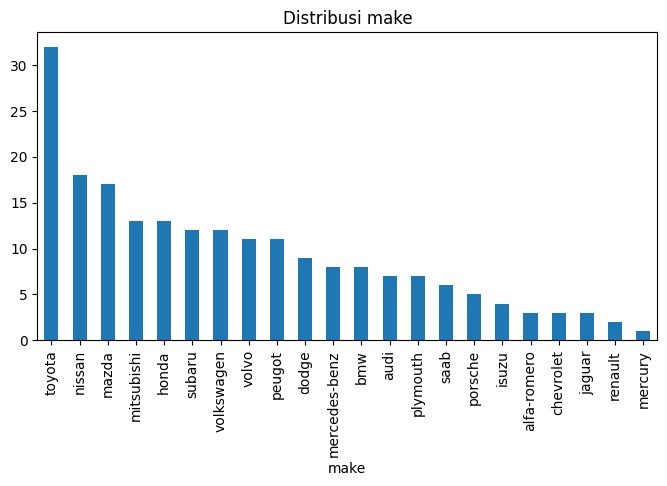

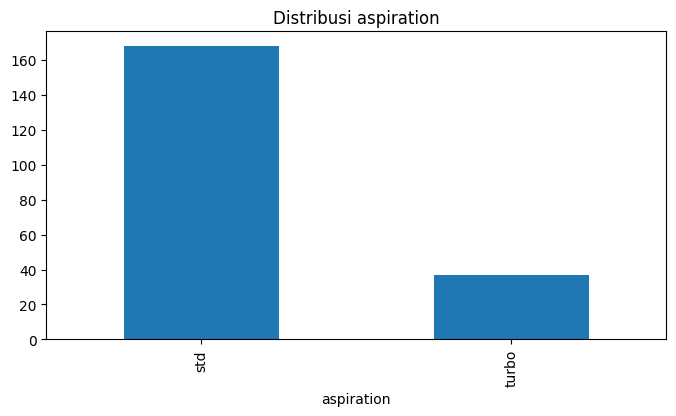

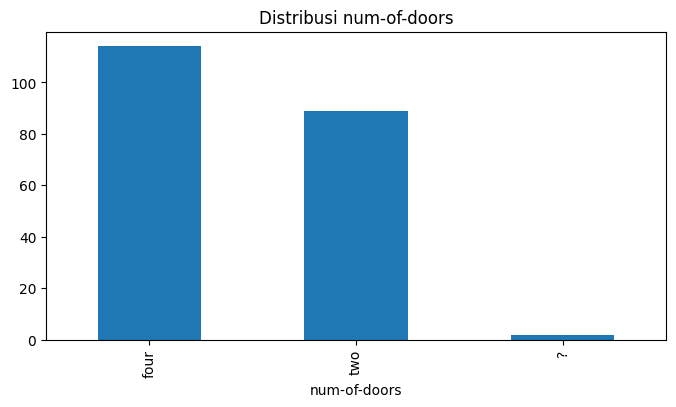

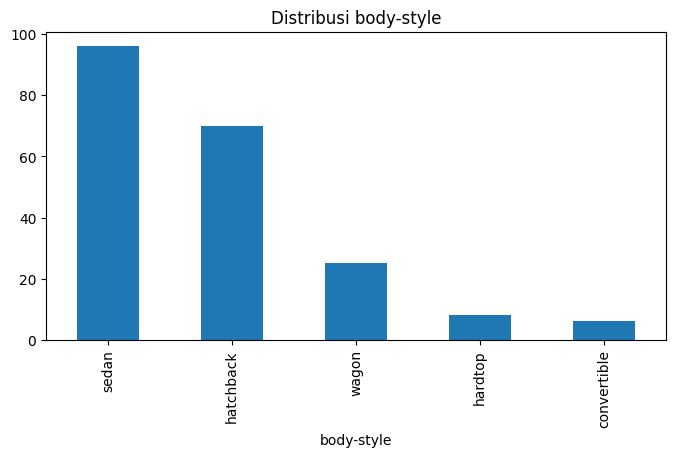

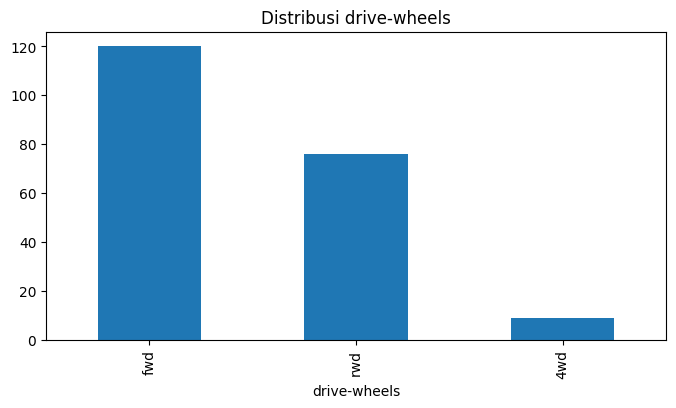

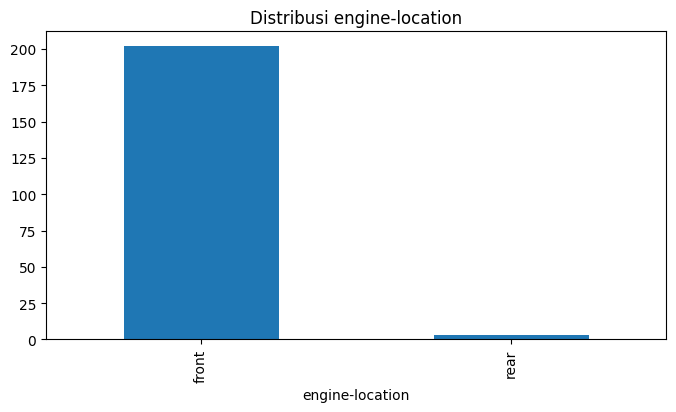

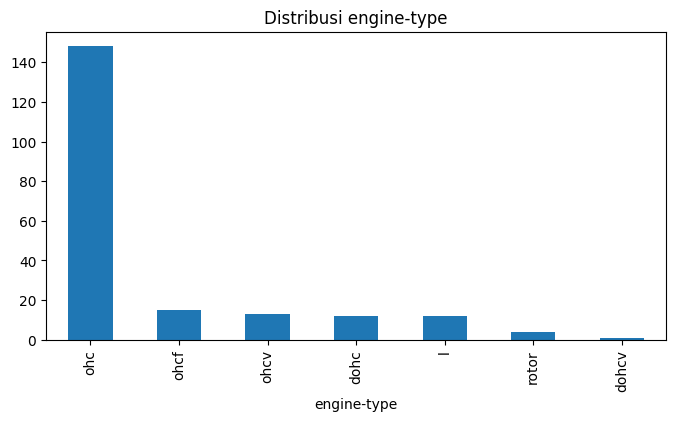

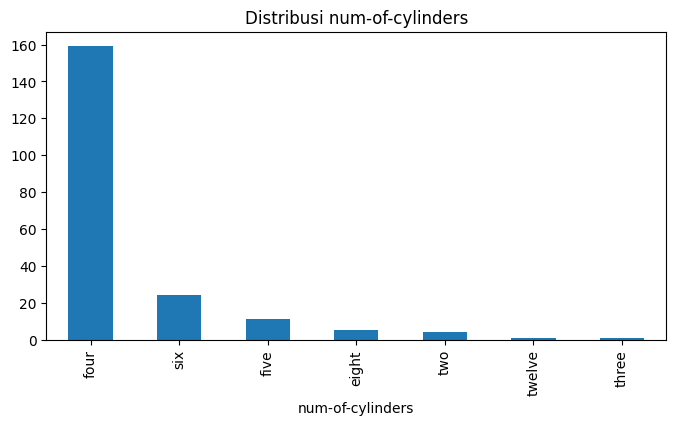

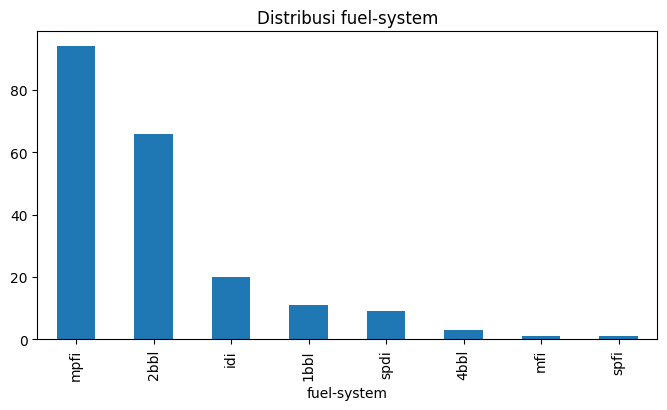

In [ ]:
categorical_cols = ['make', 'aspiration', 'num-of-doors', 'body-style', 'drive-wheels', 'engine-location', 'engine-type', 'num-of-cylinders', 'fuel-system']
for col in categorical_cols:
    plt.figure(figsize=(8, 4))
    dataset[col].value_counts().plot(kind='bar')
    plt.title(f'Distribusi {col}')
    plt.xlabel(col)

**Menampilkan visualisasi variabel Non-Kategorikal ('symboling', 'normalized-losses', 'fuel-type', 'wheel-base', 'length', 'width', 'height', 'curb-weight', 'engine-size', 'bore', 'stroke', 'compression-ratio', 'horsepower', 'peak-rpm', 'city-mpg', 'highway-mpg', 'price')**

prompt: Menampilkan histogram dari variabel 'symboling', 'normalized-losses', 'fuel-type', 'wheel-base', 'length', 'width', 'height', 'curb-weight', 'engine-size', 'bore', 'stroke', 'compression-ratio', 'horsepower', 'peak-rpm', 'city-mpg', 'highway-mpg', 'price' ke dalam 17 frame. Setiap gambar ukurannya figsize(4,3)

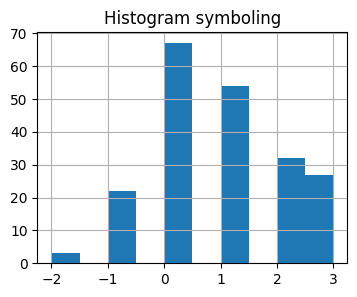

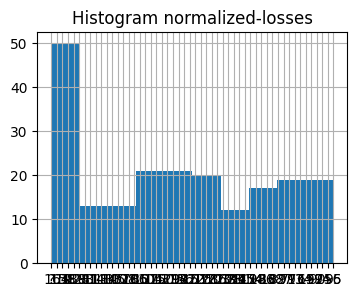

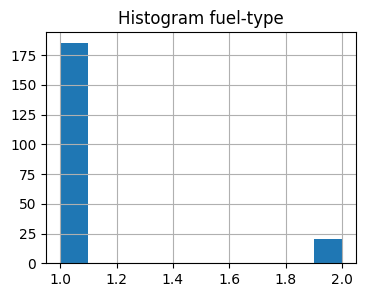

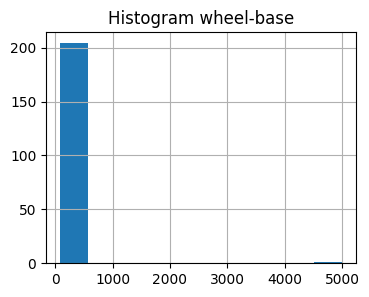

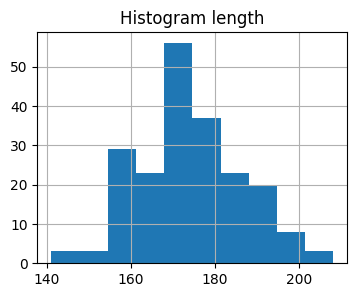

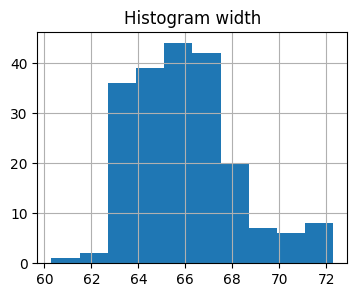

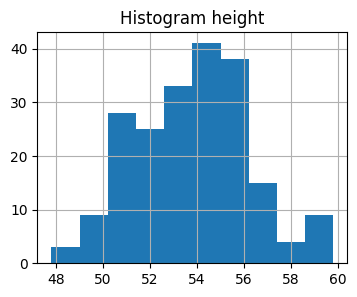

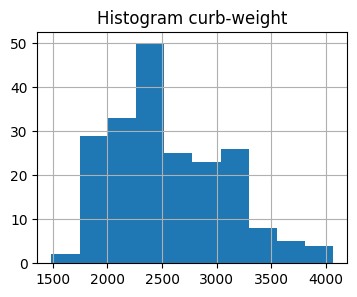

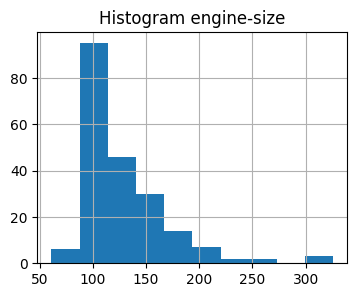

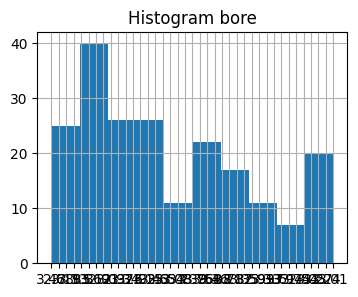

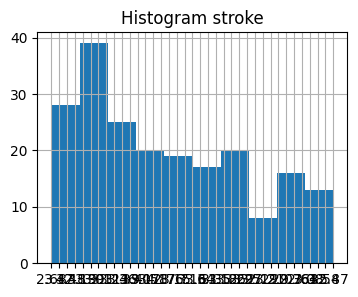

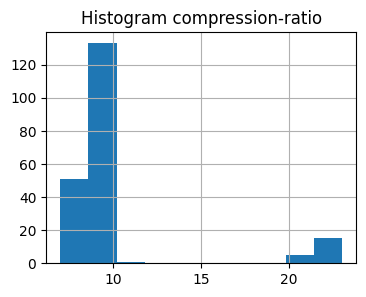

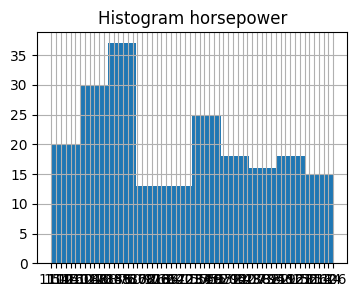

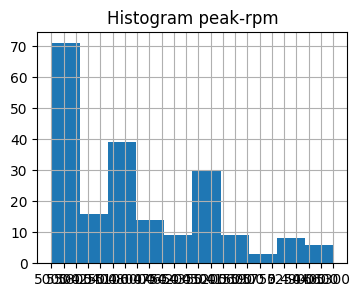

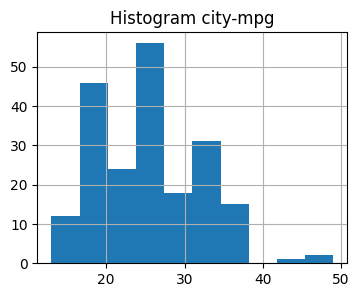

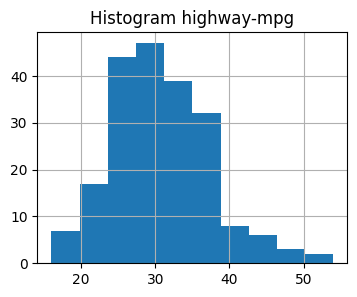

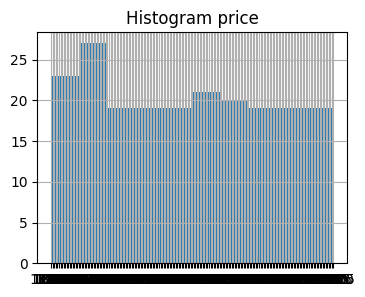

In [ ]:
non_categorical_cols = ['symboling', 'normalized-losses', 'fuel-type', 'wheel-base', 'length', 'width', 'height', 'curb-weight', 'engine-size', 'bore', 'stroke', 'compression-ratio', 'horsepower', 'peak-rpm', 'city-mpg', 'highway-mpg', 'price']
for col in non_categorical_cols:
    plt.figure(figsize=(4, 3))
    dataset[col].hist()
    plt.title(f'Histogram {col}')

**Manampilkan Box Plot Diagram dari variabel Non-Kategorikal ('symboling', 'normalized-losses', 'fuel-type', 'wheel-base', 'length', 'width', 'height', 'curb-weight', 'engine-size', 'bore', 'stroke', 'compression-ratio', 'horsepower', 'peak-rpm', 'city-mpg', 'highway-mpg', 'price')**


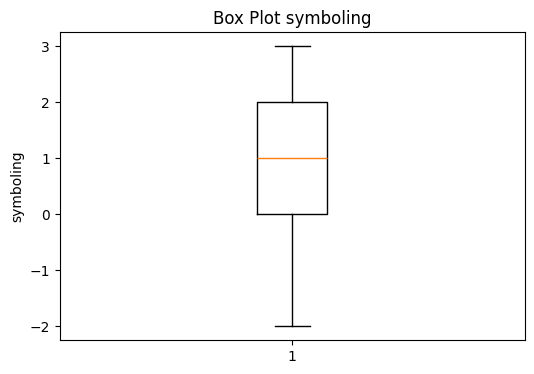

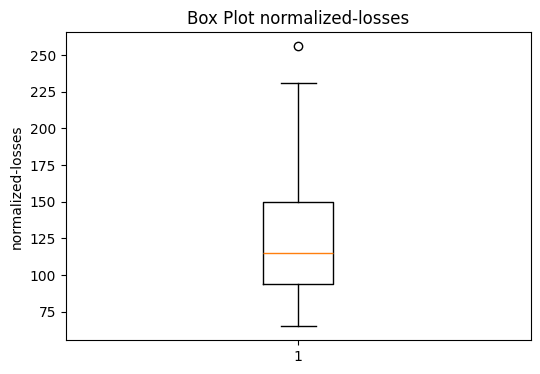

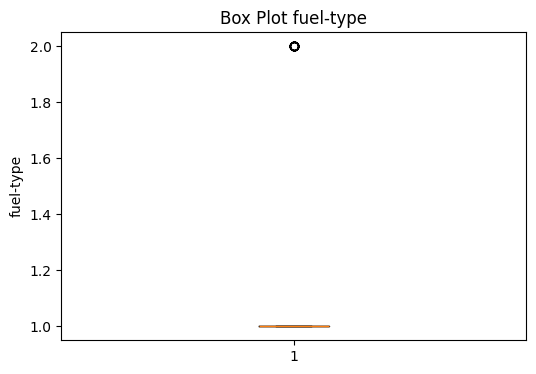

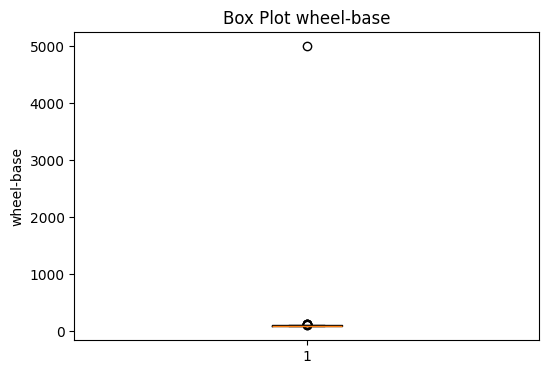

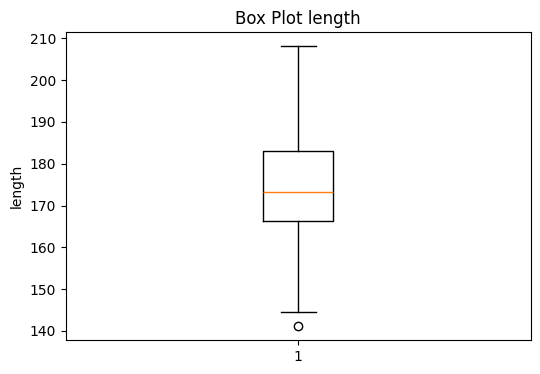

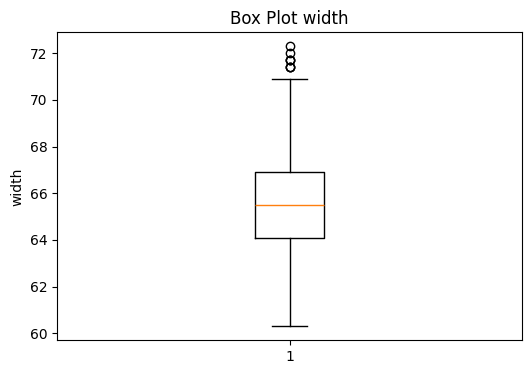

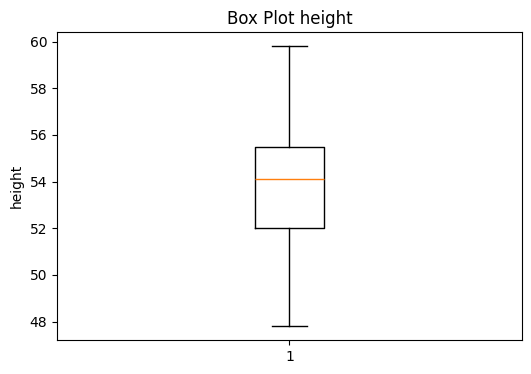

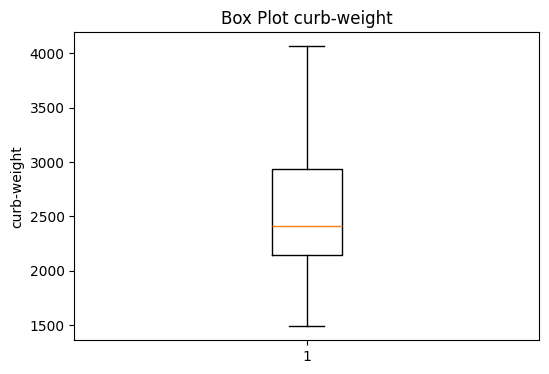

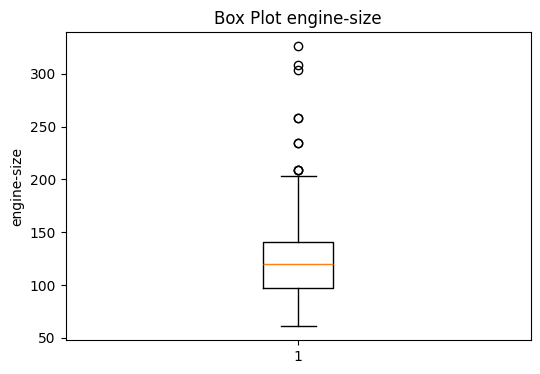

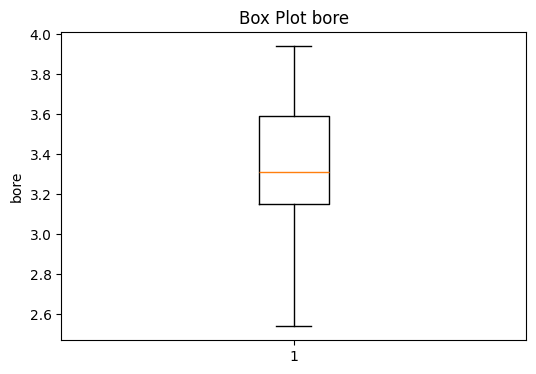

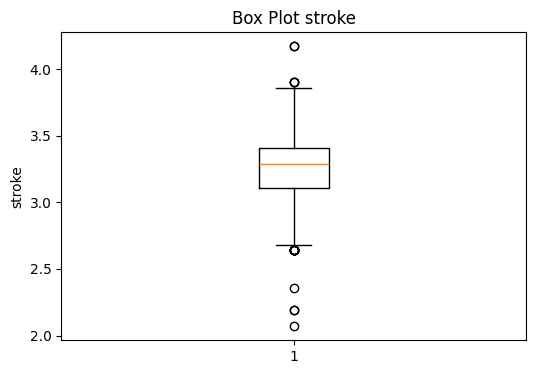

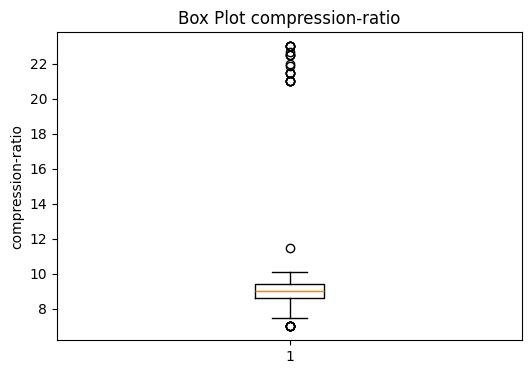

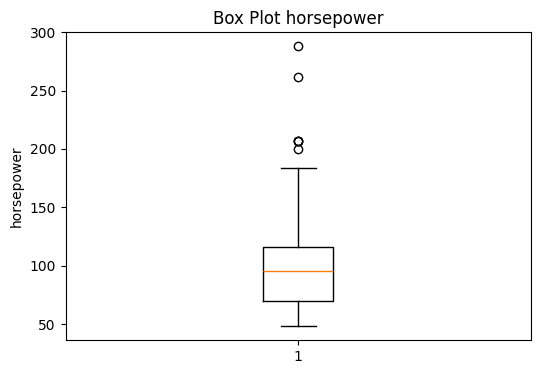

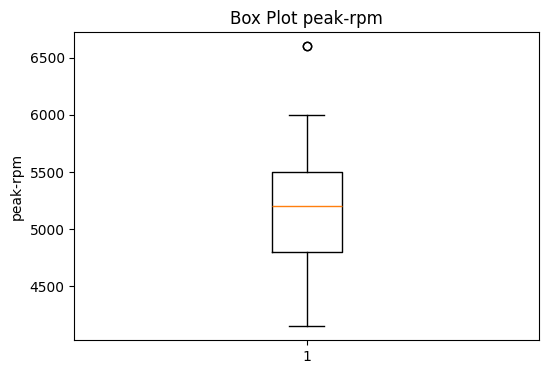

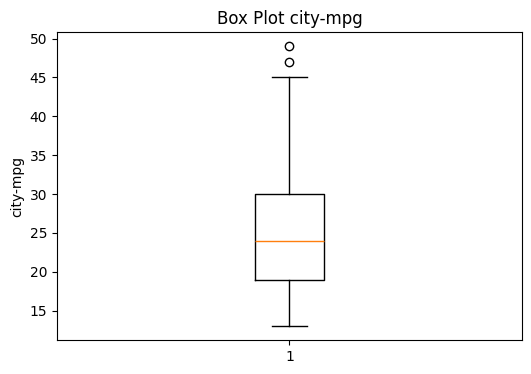

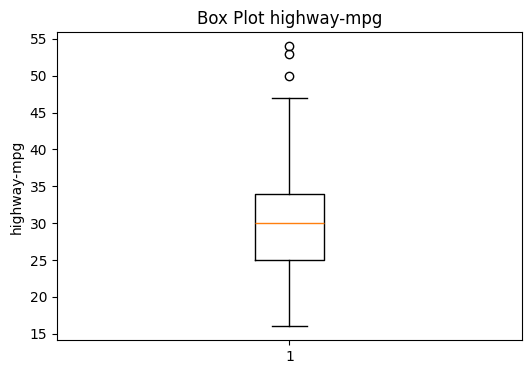

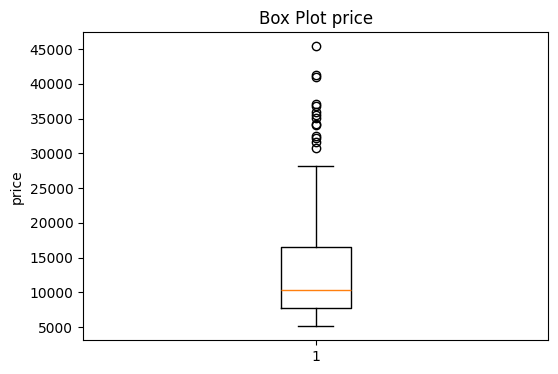

In [ ]:
non_categorical_cols = ['symboling', 'normalized-losses','fuel-type', 'wheel-base', 'length', 'width', 'height', 'curb-weight', 'engine-size', 'bore', 'stroke', 'compression-ratio', 'horsepower', 'peak-rpm', 'city-mpg', 'highway-mpg', 'price']
# Mengubah tanda ? menjadi NaN
dataset.replace('?', np.nan, inplace=True)

# Mengubah kolom menjadi numerik
for col in non_categorical_cols:
    dataset[col] = pd.to_numeric(dataset[col], errors='coerce')

# Menampilkan boxplot
for col in non_categorical_cols:
    plt.figure(figsize=(6, 4))
    plt.boxplot(dataset[col].dropna())
    plt.title(f'Box Plot {col}')
    plt.ylabel(col)
    plt.show()

**Membuat diagram Pie Chart dari variabel Kategorikal ('make', 'aspiration', 'num-of-doors', 'body-style', 'drive-wheels', 'engine-location', 'engine-type', 'num-of-cylinders', 'fuel-system')**

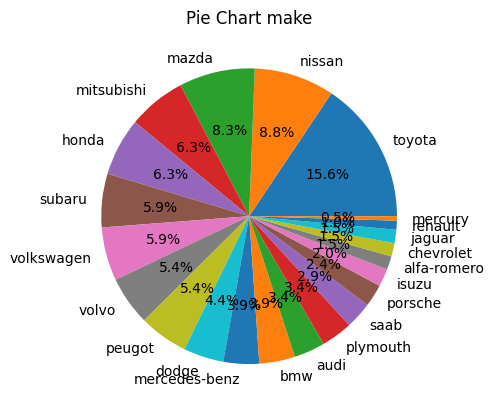

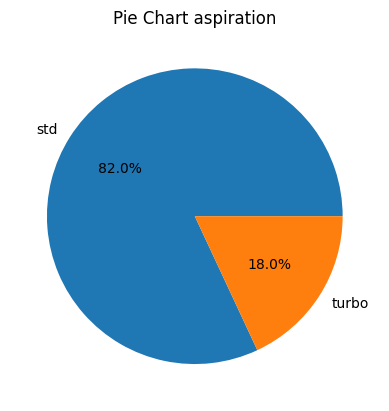

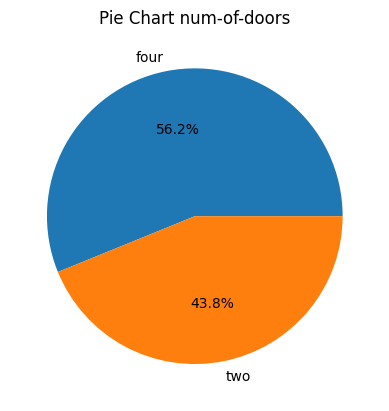

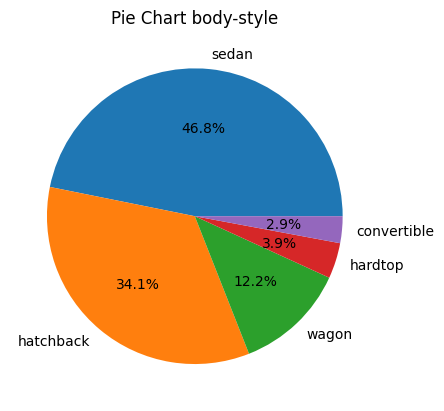

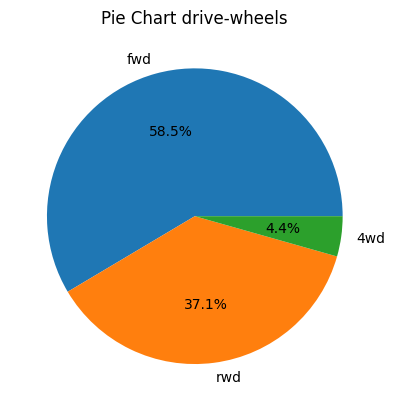

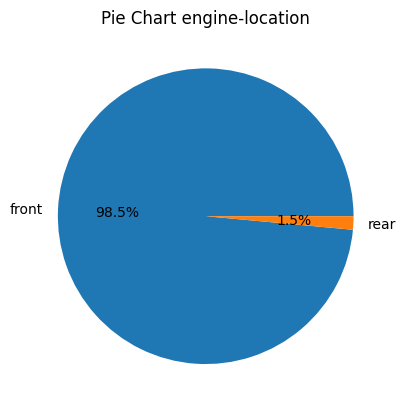

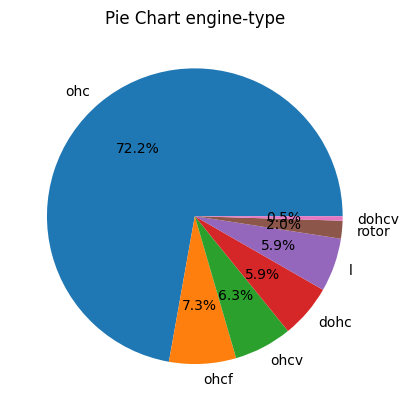

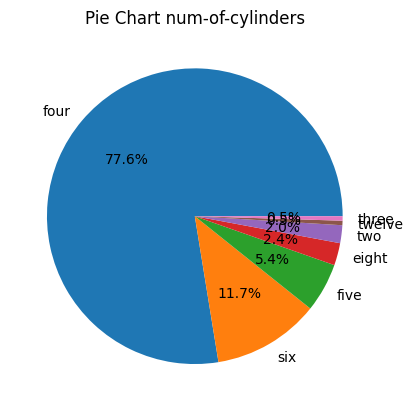

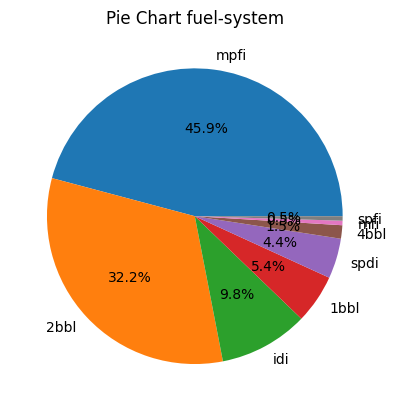

In [ ]:
categorical_cols = ['make', 'aspiration', 'num-of-doors', 'body-style', 'drive-wheels', 'engine-location', 'engine-type', 'num-of-cylinders', 'fuel-system']
for col in categorical_cols:
    plt.pie(dataset[col].value_counts(), labels=dataset[col].value_counts().index, autopct='%1.1f%%')
    plt.title(f'Pie Chart {col}')
    plt.show()

**Korelasi antar variabel numerik**

In [ ]:
numerical_cols = dataset.select_dtypes(include=np.number).columns

correlation_matrix = dataset[numerical_cols].corr(method='pearson')

display(correlation_matrix)

,symboling,normalized-losses,fuel-type,wheel-base,length,width,height,curb-weight,engine-size,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price
symboling,1.000000,0.528667,-0.194311,0.001208,-0.352818,-0.232919,-0.541038,-0.227691,-0.105790,-0.134205,-0.008965,-0.178515,0.071622,0.274573,-0.035823,0.034606,-0.082391
normalized-losses,0.528667,1.000000,-0.116736,0.079127,0.021636,0.105073,-0.432335,0.119893,0.167365,-0.036167,0.065627,-0.132654,0.295772,0.264597,-0.258502,-0.210768,0.203254
fuel-type,-0.194311,-0.116736,1.000000,-0.017969,0.212288,0.233880,0.284631,0.217275,0.069594,0.054516,0.242081,0.984356,-0.165278,-0.477314,0.255963,0.191392,0.110326
wheel-base,0.001208,0.079127,-0.017969,1.000000,0.121102,0.192982,0.065874,0.052854,0.025673,-0.028465,0.034671,-0.025028,0.017068,0.048726,-0.075978,-0.069078,0.050734
length,-0.352818,0.021636,0.212288,0.121102,1.000000,0.838085,0.483195,0.878297,0.683975,0.611560,0.121096,0.158448,0.555911,-0.290551,-0.672103,-0.705453,0.691563
width,-0.232919,0.105073,0.233880,0.192982,0.838085,1.000000,0.279210,0.867032,0.735433,0.559204,0.182956,0.181129,0.642482,-0.219957,-0.642704,-0.677218,0.751265
height,-0.541038,-0.432335,0.284631,0.065874,0.483195,0.279210,1.000000,0.295572,0.067149,0.176195,-0.056999,0.261214,-0.110711,-0.322272,-0.048640,-0.107358,0.135486
curb-weight,-0.227691,0.119893,0.217275,0.052854,0.878297,0.867032,0.295572,1.000000,0.850594,0.649045,0.168929,0.151362,0.751034,-0.266306,-0.757414,-0.797465,0.834415
engine-size,-0.105790,0.167365,0.069594,0.025673,0.683975,0.735433,0.067149,0.850594,1.000000,0.594090,0.206675,0.028971,0.810773,-0.244618,-0.653658,-0.677470,0.872335
bore,-0.134205,-0.036167,0.054516,-0.028465,0.611560,0.559204,0.176195,0.649045,0.594090,1.000000,-0.055909,0.005203,0.577273,-0.264269,-0.594584,-0.594572,0.543436


**Korelasi antara variabel Kategorikal dengan variabel Numerik**

In [ ]:
import statsmodels.api as sm
from statsmodels.formula.api import ols

# Menentukan variabel kategorikal
categorical_cols = [
    'make',
    'aspiration',
    'num-of-doors',
    'body-style',
    'drive-wheels',
    'engine-location',
    'engine-type',
    'num-of-cylinders',
    'fuel-system'
]

# Mengambil variabel numerik
numerical_cols = dataset.select_dtypes(include=np.number).columns

# Menyimpan hasil ANOVA
anova_results = {}

# Melakukan ANOVA untuk setiap kombinasi
# variabel kategorikal dan numerik
for cat_col in categorical_cols:
    for num_col in numerical_cols:

        # Menghapus missing value sementara
        temp_df = dataset[[cat_col, num_col]].dropna()

        if len(temp_df) > 0:
            try:
                # Q() digunakan karena beberapa nama kolom
                # mengandung tanda "-"
                formula = f'Q("{num_col}") ~ C(Q("{cat_col}"))'

                # Membuat model ANOVA
                model = ols(formula, data=temp_df).fit()

                # Membuat tabel ANOVA
                anova_table = sm.stats.anova_lm(
                    model,
                    typ=2
                )

                # Mengambil nilai p-value
                p_value = anova_table['PR(>F)'].iloc[0]

                anova_results[
                    f'{cat_col} vs {num_col}'
                ] = p_value

            except Exception as e:
                anova_results[
                    f'{cat_col} vs {num_col}'
                ] = f'Error: {e}'

        else:
            anova_results[
                f'{cat_col} vs {num_col}'
            ] = 'Not enough data after dropping NaNs'

# Menampilkan hasil ANOVA
print("ANOVA p-values:")

for key, value in anova_results.items():
    print(f"{key}: {value}")

ANOVA p-values:
make vs symboling: 2.0292503057459783e-13
make vs normalized-losses: 3.2807136595961876e-10
make vs fuel-type: 0.00015949882009295464
make vs wheel-base: 0.10805749566877544
make vs length: 3.1437520342874243e-34
make vs width: 6.99649850346922e-35
make vs height: 5.476273624195402e-18
make vs curb-weight: 3.8800144660637546e-35
make vs engine-size: 6.967521519841587e-33
make vs bore: 1.0979655511367699e-24
make vs stroke: 4.896405792315993e-19
make vs compression-ratio: 0.0013841433657394147
make vs horsepower: 7.873053413447851e-21
make vs peak-rpm: 6.802783385417613e-14
make vs city-mpg: 2.7286920578193185e-14
make vs highway-mpg: 2.2073716505757385e-14
make vs price: 1.0683425287775265e-50
aspiration vs symboling: 0.3938394587706009
aspiration vs normalized-losses: 0.9210718155331427
aspiration vs fuel-type: 2.4503044116566646e-09
aspiration vs wheel-base: 0.6812703166423113
aspiration vs length: 0.0007370699477809844
aspiration vs width: 1.1931619841520074e-05
aspi

**Korelasi antar variabel kategorikal**

In [ ]:
from scipy.stats import chi2_contingency
import numpy as np

def cramers_v(x, y):
    """ Calculate Cramer's V for two categorical variables. """
    contingency_table = pd.crosstab(x, y)
    chi2, p, dof, expected = chi2_contingency(contingency_table)
    n = contingency_table.sum().sum()
    phi2 = chi2 / n
    # Correct for bias
    r, k = contingency_table.shape
    phi2corr = max(0, phi2 - ((k-1)*(r-1))/(n-1))
    rcorr = r - ((r-1)**2)/(n-1)
    kcorr = k - ((k-1)**2)/(n-1)
    return np.sqrt(phi2corr / min((kcorr-1), (rcorr-1)))

# Get categorical columns
categorical_cols = dataset.select_dtypes(include='object').columns

# Calculate Cramer's V matrix
cramers_v_matrix = pd.DataFrame(index=categorical_cols, columns=categorical_cols)

for col1 in categorical_cols:
    for col2 in categorical_cols:
        if col1 == col2:
            cramers_v_matrix.loc[col1, col2] = 1.0
        else:
            cramers_v_matrix.loc[col1, col2] = cramers_v(dataset[col1], dataset[col2])

# Display Cramer's V matrix
display(cramers_v_matrix)

,make,aspiration,num-of-doors,body-style,drive-wheels,engine-location,engine-type,num-of-cylinders,fuel-system
make,1.0,0.410247,0.30023,0.317322,0.602715,0.702522,0.628502,0.543748,0.510053
aspiration,0.410247,1.0,0.0,0.0,0.118145,0.0,0.149526,0.195974,0.610237
num-of-doors,0.30023,0.0,1.0,0.747826,0.051025,0.067627,0.201365,0.134584,0.23958
body-style,0.317322,0.0,0.747826,1.0,0.213763,0.438183,0.131781,0.067532,0.143542
drive-wheels,0.602715,0.118145,0.051025,0.213763,1.0,0.12442,0.425424,0.336,0.387229
engine-location,0.702522,0.0,0.067627,0.438183,0.12442,1.0,0.399361,0.288097,0.0
engine-type,0.628502,0.149526,0.201365,0.131781,0.425424,0.399361,1.0,0.545675,0.376842
num-of-cylinders,0.543748,0.195974,0.134584,0.067532,0.336,0.288097,0.545675,1.0,0.373307
fuel-system,0.510053,0.610237,0.23958,0.143542,0.387229,0.0,0.376842,0.373307,1.0


# **Validasi Data: mengidentifikasi sampel data yang tidak valid**

# **Pembersihan Data: menangani sampel data yang tidak valid**

**1. Mengidentifikasi variabel data yang memiliki nilai  kosong**

In [ ]:
# Menampilkan jumlah nilai kosong per variabel
print(dataset.isnull().sum())

symboling             0
normalized-losses    41
make                  0
fuel-type             0
aspiration            0
num-of-doors          2
body-style            0
drive-wheels          0
engine-location       0
wheel-base            0
length                0
width                 0
height                0
curb-weight           0
engine-type           0
num-of-cylinders      0
engine-size           0
fuel-system           0
bore                  4
stroke                4
compression-ratio     0
horsepower            2
peak-rpm              2
city-mpg              0
highway-mpg           0
price                 4
dtype: int64


**2.  Menangani nilai variabel yang kosong**

In [ ]:
# Menangani nilai variabel yang kosong

# 1. Menghapus baris yang memiliki nilai kosong pada target 'price'
dataset = dataset.dropna(subset=['price'])

# 2. Mengisi missing value pada variabel numerik menggunakan median
numerical_missing_cols = [
    'normalized-losses',
    'bore',
    'stroke',
    'horsepower',
    'peak-rpm'
]

for col in numerical_missing_cols:
    dataset[col] = dataset[col].fillna(dataset[col].median())

# 3. Mengisi missing value pada variabel kategorikal menggunakan modus
dataset['num-of-doors'] = dataset['num-of-doors'].fillna(
    dataset['num-of-doors'].mode()[0]
)

# Mengecek kembali missing value
print(dataset.isnull().sum())

symboling            0
normalized-losses    0
make                 0
fuel-type            0
aspiration           0
num-of-doors         0
body-style           0
drive-wheels         0
engine-location      0
wheel-base           0
length               0
width                0
height               0
curb-weight          0
engine-type          0
num-of-cylinders     0
engine-size          0
fuel-system          0
bore                 0
stroke               0
compression-ratio    0
horsepower           0
peak-rpm             0
city-mpg             0
highway-mpg          0
price                0
dtype: int64


**3. Mengidentifikasi variabel numerik yang memiliki nilai outlier**

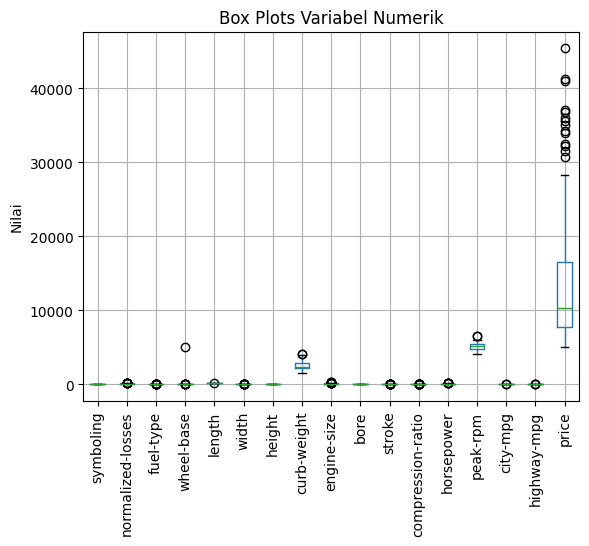

In [ ]:
# Mengidentifikasi variabel numerik
numerical_cols = dataset.select_dtypes(include=np.number).columns

# Membuat box plot untuk setiap variabel numerik dalam satu frame dengan label vertikal
dataset[numerical_cols].boxplot(rot=90)
plt.title('Box Plots Variabel Numerik')
plt.ylabel('Nilai')
plt.show()

**4. Menangani nilai outlier dari variabel menggunakan metode IQR**

In [ ]:
# ============================================================
# MENANGANI OUTLIER DENGAN METODE IQR
# ============================================================

numerical_cols_to_handle = [
    'normalized-losses',
    'wheel-base',
    'length',
    'width',
    'height',
    'curb-weight',
    'engine-size',
    'bore',
    'stroke',
    'compression-ratio',
    'horsepower',
    'peak-rpm',
    'city-mpg',
    'highway-mpg'
]

outlier_handling_summary = []

for col in numerical_cols_to_handle:

    if col not in dataset.columns:
        continue

    Q1 = dataset[col].quantile(0.25)
    Q3 = dataset[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outlier_before = (
        (dataset[col] < lower_bound) |
        (dataset[col] > upper_bound)
    ).sum()

    # Hanya menangani variabel yang memiliki outlier
    if outlier_before > 0:
        dataset[col] = dataset[col].clip(
            lower=lower_bound,
            upper=upper_bound
        )

    outlier_after = (
        (dataset[col] < lower_bound) |
        (dataset[col] > upper_bound)
    ).sum()

    if outlier_before > 0:
        outlier_handling_summary.append({
            'Variabel': col,
            'Q1': Q1,
            'Q3': Q3,
            'IQR': IQR,
            'Lower Bound': lower_bound,
            'Upper Bound': upper_bound,
            'Outlier Sebelum': outlier_before,
            'Outlier Sesudah': outlier_after
        })

display(pd.DataFrame(outlier_handling_summary))

,Variabel,Q1,Q3,IQR,Lower Bound,Upper Bound,Outlier Sebelum,Outlier Sesudah
0,normalized-losses,101.00,137.00,36.0,47.00,191.00,8,0
1,length,166.80,183.50,16.7,141.75,208.55,1,0
2,width,64.10,66.60,2.5,60.35,70.35,11,0
3,curb-weight,2169.00,2926.00,757.0,1033.50,4061.50,2,0
4,engine-size,98.00,141.00,43.0,33.50,205.50,10,0
5,stroke,3.11,3.41,0.3,2.66,3.86,20,0
6,compression-ratio,8.60,9.40,0.8,7.40,10.60,27,0
7,horsepower,70.00,116.00,46.0,1.00,185.00,5,0
8,city-mpg,19.00,30.00,11.0,2.50,46.50,2,0
9,highway-mpg,25.00,34.00,9.0,11.50,47.50,3,0


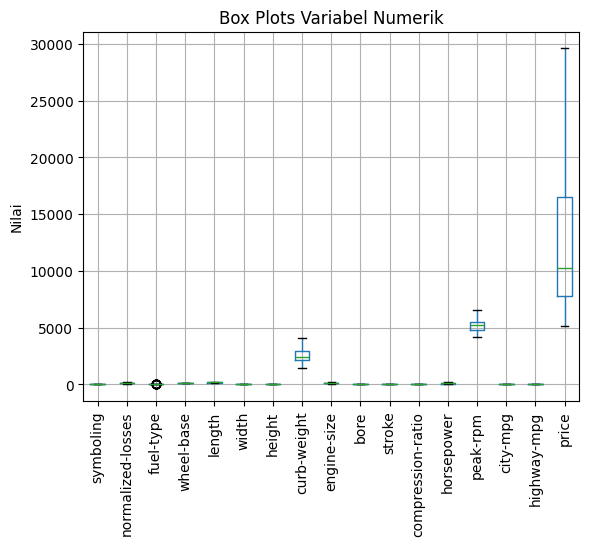

In [ ]:
# Mengidentifikasi variabel numerik
numerical_cols = dataset.select_dtypes(include=np.number).columns

# Membuat box plot untuk setiap variabel numerik dalam satu frame dengan label vertikal
dataset[numerical_cols].boxplot(rot=90)
plt.title('Box Plots Variabel Numerik')
plt.ylabel('Nilai')
plt.show()

# **Konstruksi Data**

**Mengkonversi nilai fitur kategorikal menjadi numerik menggunakan ordinal encoder**

In [ ]:
# ============================================================
# ORDINAL ENCODING VARIABEL KATEGORIKAL
# ============================================================
from sklearn.preprocessing import OrdinalEncoder

categorical_cols = dataset.select_dtypes(include='object').columns.tolist()

if categorical_cols:
    ordinal_encoder = OrdinalEncoder(
        handle_unknown='use_encoded_value',
        unknown_value=-1
    )

    dataset[categorical_cols] = ordinal_encoder.fit_transform(
        dataset[categorical_cols]
    )

    print("Variabel kategorikal yang di-encode:")
    print(categorical_cols)

    # Menampilkan pemetaan kategori untuk membantu interpretasi.
    for col, categories in zip(categorical_cols, ordinal_encoder.categories_):
        mapping = {category: idx for idx, category in enumerate(categories)}
        print(f"{col}: {mapping}")
else:
    print("Tidak ada variabel bertipe object yang perlu di-encode.")

display(dataset.head())


Variabel kategorikal yang di-encode:
['make', 'aspiration', 'num-of-doors', 'body-style', 'drive-wheels', 'engine-location', 'engine-type', 'num-of-cylinders', 'fuel-system']
make: {'alfa-romero': 0, 'audi': 1, 'bmw': 2, 'chevrolet': 3, 'dodge': 4, 'honda': 5, 'isuzu': 6, 'jaguar': 7, 'mazda': 8, 'mercedes-benz': 9, 'mercury': 10, 'mitsubishi': 11, 'nissan': 12, 'peugot': 13, 'plymouth': 14, 'porsche': 15, 'renault': 16, 'saab': 17, 'subaru': 18, 'toyota': 19, 'volkswagen': 20, 'volvo': 21}
aspiration: {'std': 0, 'turbo': 1}
num-of-doors: {'four': 0, 'two': 1}
body-style: {'convertible': 0, 'hardtop': 1, 'hatchback': 2, 'sedan': 3, 'wagon': 4}
drive-wheels: {'4wd': 0, 'fwd': 1, 'rwd': 2}
engine-location: {'front': 0, 'rear': 1}
engine-type: {'dohc': 0, 'l': 1, 'ohc': 2, 'ohcf': 3, 'ohcv': 4, 'rotor': 5}
num-of-cylinders: {'eight': 0, 'five': 1, 'four': 2, 'six': 3, 'three': 4, 'twelve': 5, 'two': 6}
fuel-system: {'1bbl': 0, '2bbl': 1, '4bbl': 2, 'idi': 3, 'mfi': 4, 'mpfi': 5, 'spdi': 6

,symboling,normalized-losses,make,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,...,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price
0,3,115.0,0.0,1,0.0,1.0,0.0,2.0,0.0,114.25,...,130.0,5.0,3.47,2.68,9.0,111.0,5000.0,21.0,27.0,13495.0
1,3,115.0,0.0,1,0.0,1.0,0.0,2.0,0.0,88.60,...,130.0,5.0,3.47,2.68,9.0,111.0,5000.0,21.0,27.0,16500.0
2,1,115.0,0.0,1,0.0,1.0,2.0,2.0,0.0,114.25,...,152.0,5.0,2.68,3.47,9.0,154.0,5000.0,19.0,26.0,16500.0
3,2,164.0,1.0,1,0.0,0.0,3.0,1.0,0.0,99.80,...,109.0,5.0,3.19,3.40,10.0,102.0,5500.0,24.0,30.0,13950.0
4,2,164.0,1.0,1,0.0,0.0,3.0,0.0,0.0,114.25,...,136.0,5.0,3.19,3.40,8.0,115.0,5500.0,18.0,22.0,17450.0


In [ ]:
print(dataset.dtypes)

symboling              int64
normalized-losses    float64
make                 float64
fuel-type              int64
aspiration           float64
num-of-doors         float64
body-style           float64
drive-wheels         float64
engine-location      float64
wheel-base           float64
length               float64
width                float64
height               float64
curb-weight          float64
engine-type          float64
num-of-cylinders     float64
engine-size          float64
fuel-system          float64
bore                 float64
stroke               float64
compression-ratio    float64
horsepower           float64
peak-rpm             float64
city-mpg             float64
highway-mpg          float64
price                float64
dtype: object


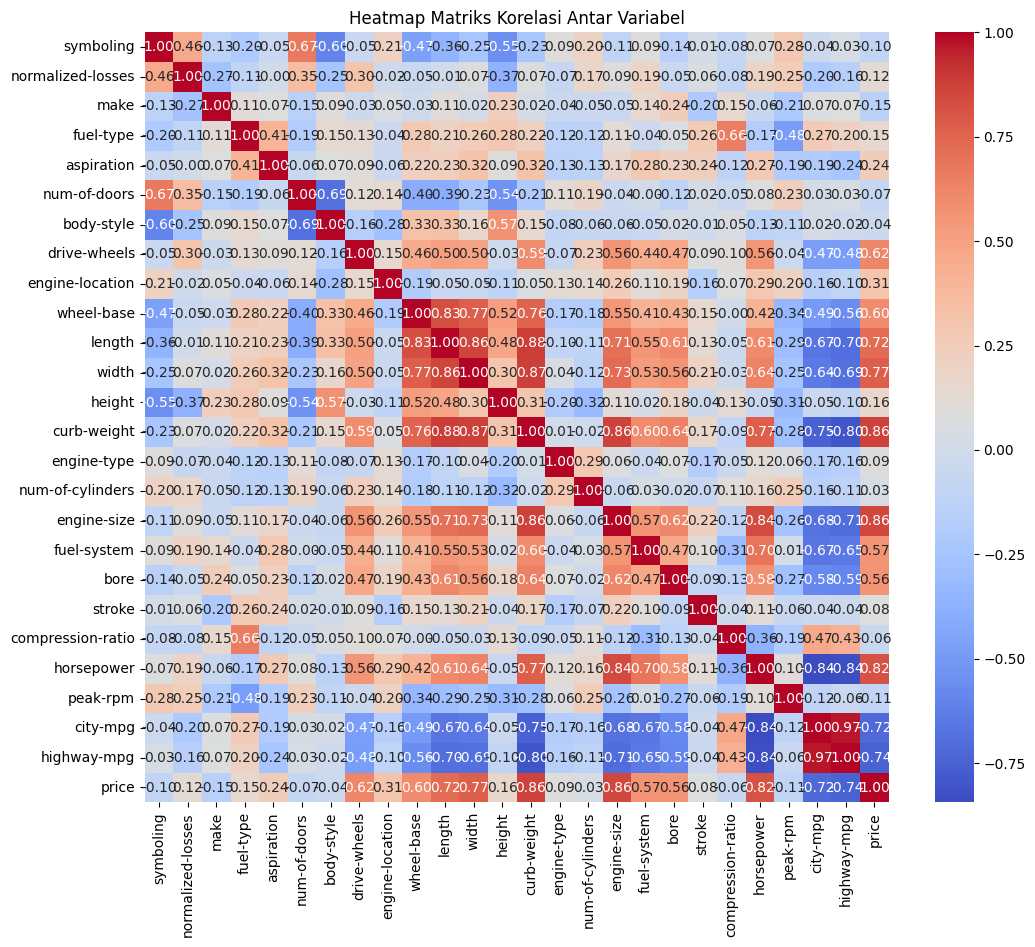

In [ ]:
import seaborn as sns

# Hitung matriks korelasi
correlation_matrix = dataset.corr()

# Buat heatmap
plt.figure(figsize=(12, 10))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Heatmap Matriks Korelasi Antar Variabel')
plt.show()

# **Pemilihan Objek Data: pemilihan fitur data**

**1. Menghitung Skor Feature Importance setiap variabel**

In [ ]:
# Hitung matriks korelasi
correlation_matrix = dataset.corr()

# Urutkan variabel berdasarkan nilai absolut koefisien korelasi terhadap price
correlation_with_price = correlation_matrix['price'].abs().sort_values(ascending=False)

# Tampilkan hasil
print("Urutan variabel berdasarkan nilai absolut koefisien korelasi terhadap price:")
print(correlation_with_price)

Urutan variabel berdasarkan nilai absolut koefisien korelasi terhadap price:
price                1.000000
curb-weight          0.864556
engine-size          0.855664
horsepower           0.816135
width                0.772948
highway-mpg          0.742944
length               0.723785
city-mpg             0.719705
drive-wheels         0.620854
wheel-base           0.598722
fuel-system          0.565999
bore                 0.562902
engine-location      0.311728
aspiration           0.241590
height               0.161092
make                 0.149994
fuel-type            0.148842
normalized-losses    0.124567
peak-rpm             0.108191
symboling            0.095307
engine-type          0.085773
stroke               0.077342
num-of-doors         0.074895
compression-ratio    0.061965
body-style           0.042829
num-of-cylinders     0.031076
Name: price, dtype: float64


**2. Menghitung Skor SHAP setiap variabel dengan model XGBoost**

In [ ]:
!pip install shap

In [ ]:
# Menyiapkan data fitur dan label untuk analisis SHAP
X_shap = X.copy()
y_shap = y.copy()

print('Data SHAP siap digunakan.')
print('Bentuk X_shap:', X_shap.shape)
print('Bentuk y_shap:', y_shap.shape)


Data SHAP siap digunakan.
Bentuk X_shap: (201, 25)
Bentuk y_shap: (201,)


In [ ]:
import xgboost as xgb

# Inisialisasi dan latih model XGBoost Classifier
xgb_model = xgb.XGBRegressor(random_state=42)
xgb_model.fit(X, y)

print("Model XGBoost telah dilatih.")

Model XGBoost telah dilatih.


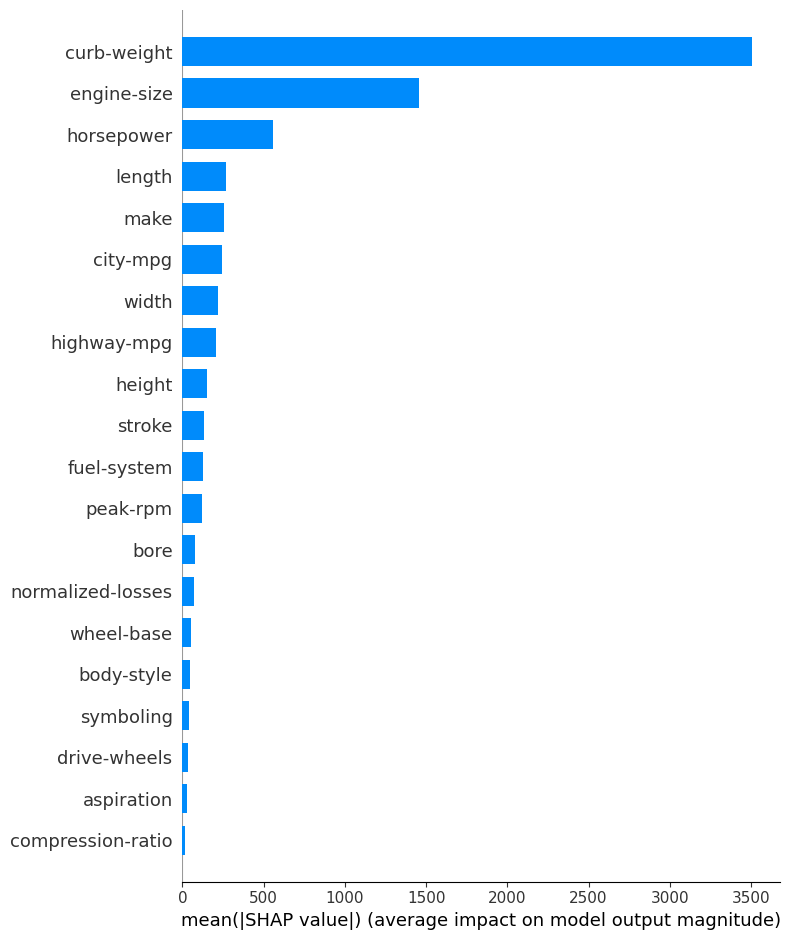

In [ ]:
import shap

# Inisialisasi SHAP explainer untuk model XGBoost
explainer_xgb = shap.TreeExplainer(xgb_model)

# Hitung nilai SHAP untuk data menggunakan model XGBoost
shap_values_xgb = explainer_xgb.shap_values(X)

# Ringkasan plot SHAP untuk model XGBoost
shap.summary_plot(shap_values_xgb, X, plot_type="bar")

# **Mengkonstruksi (Mentransformasi Fitur) Data**

**1.  Normalisasi Fitur Data**

In [ ]:
from sklearn.preprocessing import MinMaxScaler

# Normalisasi Fitur ke rentang 0 sampai 1
minmax_scaler = MinMaxScaler()
X_normalized = pd.DataFrame(
    minmax_scaler.fit_transform(X),
    columns=X.columns,
    index=X.index
)

display(X_normalized.head())

,symboling,normalized-losses,make,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,...,num-of-cylinders,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg
0,1.0,0.396825,0.000000,0.0,0.0,1.0,0.00,1.0,0.0,1.000000,...,0.333333,0.477509,0.714286,0.664286,0.016667,0.5000,0.459854,0.354167,0.238806,0.349206
1,1.0,0.396825,0.000000,0.0,0.0,1.0,0.00,1.0,0.0,0.072333,...,0.333333,0.477509,0.714286,0.664286,0.016667,0.5000,0.459854,0.354167,0.238806,0.349206
2,0.6,0.396825,0.000000,0.0,0.0,1.0,0.50,1.0,0.0,1.000000,...,0.500000,0.629758,0.714286,0.100000,0.675000,0.5000,0.773723,0.354167,0.179104,0.317460
3,0.8,0.785714,0.047619,0.0,0.0,0.0,0.75,0.5,0.0,0.477396,...,0.333333,0.332180,0.714286,0.464286,0.616667,0.8125,0.394161,0.562500,0.328358,0.444444
4,0.8,0.785714,0.047619,0.0,0.0,0.0,0.75,0.0,0.0,1.000000,...,0.166667,0.519031,0.714286,0.464286,0.616667,0.1875,0.489051,0.562500,0.149254,0.190476


**2.  Standardisasi Fitur Data**

In [ ]:
from sklearn.preprocessing import StandardScaler

# Standardisasi Fitur
standard_scaler = StandardScaler()
X_standardized = pd.DataFrame(
    standard_scaler.fit_transform(X),
    columns=X.columns,
    index=X.index
)

display(X_standardized.head())

,symboling,normalized-losses,make,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,...,num-of-cylinders,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg
0,1.725050,-0.168830,-1.971717,-0.332411,-0.467099,1.156378,-3.034335,1.213477,-0.123091,2.434935,...,-0.171457,0.167053,0.867123,0.522405,-2.099927,-0.046969,0.242268,-0.247987,-0.655281,-0.548697
1,1.725050,-0.168830,-1.971717,-0.332411,-0.467099,1.156378,-3.034335,1.213477,-0.123091,-1.685481,...,-0.171457,0.167053,0.867123,0.522405,-2.099927,-0.046969,0.242268,-0.247987,-0.655281,-0.548697
2,0.127193,-0.168830,-1.971717,-0.332411,-0.467099,1.156378,-0.715318,1.213477,-0.123091,2.434935,...,1.104946,0.825438,0.867123,-2.431752,0.740340,-0.046969,1.471816,-0.247987,-0.970004,-0.700505
3,0.926121,1.456595,-1.811395,-0.332411,-0.467099,-0.864769,0.444190,-0.606739,-0.123091,0.113687,...,-0.171457,-0.461405,0.867123,-0.524638,0.488671,1.225381,-0.015079,0.803603,-0.183197,-0.093275
4,0.926121,1.456595,-1.811395,-0.332411,-0.467099,-0.864769,0.444190,-2.426955,-0.123091,2.434935,...,-1.447860,0.346612,0.867123,-0.524638,0.488671,-1.319320,0.356644,0.803603,-1.127365,-1.307735


**3. Binning**

In [ ]:
from sklearn.preprocessing import KBinsDiscretizer

# Fitur numerik kontinu yang akan dilakukan binning
binning_cols = [
    'normalized-losses',
    'wheel-base',
    'length',
    'width',
    'height',
    'curb-weight',
    'engine-size',
    'bore',
    'stroke',
    'compression-ratio',
    'horsepower',
    'peak-rpm',
    'city-mpg',
    'highway-mpg'
]

# Menyalin data X agar data asli tidak berubah
X_binned = X.copy()

# Membuat binning menjadi 5 kelompok
binning = KBinsDiscretizer(
    n_bins=5,
    encode='ordinal',
    strategy='quantile'
)

# Melakukan binning
X_binned[binning_cols] = binning.fit_transform(
    X[binning_cols]
)

display(X_binned.head())

,symboling,normalized-losses,make,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,...,num-of-cylinders,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg
0,3,2.0,0.0,1,0.0,1.0,0.0,2.0,0.0,4.0,...,2.0,3.0,5.0,3.0,0.0,2.0,3.0,2.0,1.0,1.0
1,3,2.0,0.0,1,0.0,1.0,0.0,2.0,0.0,0.0,...,2.0,3.0,5.0,3.0,0.0,2.0,3.0,2.0,1.0,1.0
2,1,2.0,0.0,1,0.0,1.0,2.0,2.0,0.0,4.0,...,3.0,4.0,5.0,0.0,4.0,2.0,4.0,2.0,1.0,1.0
3,2,4.0,1.0,1,0.0,0.0,3.0,1.0,0.0,3.0,...,2.0,2.0,5.0,2.0,3.0,4.0,3.0,4.0,2.0,2.0
4,2,4.0,1.0,1,0.0,0.0,3.0,0.0,0.0,4.0,...,1.0,3.0,5.0,2.0,3.0,0.0,3.0,4.0,0.0,0.0


In [ ]:
display(
    pd.DataFrame({
        'horsepower_asli': X['horsepower'],
        'horsepower_binning': X_binned['horsepower']
    }).head(20)
)

,horsepower_asli,horsepower_binning
0,111.0,3.0
1,111.0,3.0
2,154.0,4.0
3,102.0,3.0
4,115.0,3.0
5,110.0,3.0
6,110.0,3.0
7,110.0,3.0
8,140.0,4.0
10,101.0,2.0


**4.  Principal Component Analysis (PCA)**

In [ ]:
from sklearn.decomposition import PCA

# PCA menggunakan data yang telah distandardisasi
pca = PCA(n_components=0.95)

X_pca = pca.fit_transform(X_standardized)

# Mengubah hasil PCA menjadi DataFrame
X_pca = pd.DataFrame(
    X_pca,
    columns=[
        f'PC{i+1}'
        for i in range(X_pca.shape[1])
    ],
    index=X.index
)

print("Jumlah fitur sebelum PCA:", X_standardized.shape[1])
print("Jumlah komponen setelah PCA:", X_pca.shape[1])

display(X_pca.head())

Jumlah fitur sebelum PCA: 25
Jumlah komponen setelah PCA: 16


,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,PC11,PC12,PC13,PC14,PC15,PC16
0,0.641181,2.803151,1.320935,0.548552,-0.528516,-2.317219,-1.936054,-0.963195,-0.509550,-2.332614,-1.322327,0.962049,2.526670,1.469809,0.361240,-1.196983
1,-0.507872,3.562068,1.245035,0.041603,-1.107648,-1.895157,-1.460393,-0.581070,-0.344009,-2.288560,-0.400963,0.714778,1.817473,1.814470,0.347475,0.028063
2,1.500552,2.063078,0.354744,0.857999,2.271502,1.833550,-1.154730,-0.215015,0.411483,0.184946,-1.342562,0.354608,2.159467,-2.038591,-0.043848,0.086048
3,-0.257948,0.444546,0.050484,1.382909,1.556561,-0.510904,-0.011917,0.536458,-1.168316,1.268660,0.692347,0.186029,0.616226,0.727355,0.816845,-0.295805
4,1.488034,0.547386,-1.648372,2.921555,0.045522,0.118726,-1.007795,0.447191,-1.861173,1.733409,0.655456,0.719050,0.927039,0.470821,0.032256,-0.853815


# **Penentuan Label Data**

In [ ]:
from sklearn.preprocessing import OrdinalEncoder
import numpy as np
import pandas as pd

# --- Langkah Pembersihan dan Encoding yang Relevan ---
# Mengidentifikasi variabel kategorikal yang akan di-encode
categorical_cols_to_encode = dataset.select_dtypes(include='object').columns.tolist()

# Inisialisasi OrdinalEncoder
# Menangani nilai yang tidak diketahui (unknown values) dengan 'use_encoded_value'
# Menangani nilai yang hilang (missing values) dengan 'encoded_missing_value'
ordinal_encoder = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1, encoded_missing_value=-1)

# Terapkan Ordinal Encoding pada kolom kategorikal
# Membuat salinan dataset untuk menghindari peringatan SettingWithCopyWarning
dataset_encoded = dataset.copy()
dataset_encoded[categorical_cols_to_encode] = ordinal_encoder.fit_transform(dataset_encoded[categorical_cols_to_encode])

# Menghapus baris yang mengandung nilai NaN dari dataset yang sudah di-encode
dataset_cleaned_nan = dataset_encoded.dropna().copy()
# --- Akhir Langkah Pembersihan dan Encoding ---


# Pisahkan fitur (X) dan target (y)
# Menggunakan dataset_cleaned_nan yang sudah dibersihkan dan di-encode
X = dataset_cleaned_nan.drop('price', axis=1)
y = dataset_cleaned_nan['price']

print("Variabel fitur (X) dan variabel target (y) telah dibagi.")
print("Bentuk matriks X:", X.shape)
print("Bentuk vektor y:", y.shape)

Variabel fitur (X) dan variabel target (y) telah dibagi.
Bentuk matriks X: (201, 25)
Bentuk vektor y: (201,)


# **Pemodelan Data**

**1. Membuat Salinan Data**

In [ ]:
OldDataset = dataset

**2. Membagi dataset menjadi matriks data dan vektor target**


In [ ]:
# Membagi dataset menjadi matriks fitur (X) dan target (y)

X = OldDataset.drop('price', axis=1)
y = OldDataset['price']

print("Dataset telah dibagi menjadi fitur dan target.")
print("Bentuk X:", X.shape)
print("Bentuk y:", y.shape)

Dataset telah dibagi menjadi fitur dan target.
Bentuk X: (201, 25)
Bentuk y: (201,)


**3. Hold-out Cross Validation**

In [ ]:
from sklearn.model_selection import train_test_split

# Hold-out validation
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Hold-out validation selesai.")
print("Jumlah data training:", len(X_train))
print("Jumlah data testing :", len(X_test))

print("Bentuk X_train:", X_train.shape)
print("Bentuk X_test :", X_test.shape)
print("Bentuk y_train:", y_train.shape)
print("Bentuk y_test :", y_test.shape)

Hold-out validation selesai.
Jumlah data training: 160
Jumlah data testing : 41
Bentuk X_train: (160, 25)
Bentuk X_test : (41, 25)
Bentuk y_train: (160,)
Bentuk y_test : (41,)


# **Pemodelan Model Linier**

**1.  Training Model Linier**

Prompt: Training model Linier. Training Model Linier menggunakan X_train dan y_train. Testing Model Linier menggunakan X_test dan y_test. Metriks kinerja model: MAE, RMSE, dan R square.

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# ============================================================
# TRAINING MODEL LINIER
# ============================================================

# 1. Inisialisasi model
linear_model = LinearRegression()

# 2. Training model menggunakan X_train dan y_train
linear_model.fit(X_train, y_train)

# 3. Testing model menggunakan X_test
y_pred_linear = linear_model.predict(X_test)

# 4. Menghitung metrik kinerja
mae_linear = mean_absolute_error(y_test, y_pred_linear)
rmse_linear = np.sqrt(mean_squared_error(y_test, y_pred_linear))
r2_linear = r2_score(y_test, y_pred_linear)

**Menampilkan model linier hasil training**

In [ ]:
# 5. Menampilkan hasil evaluasi
print("Hasil Evaluasi Model Linear Regression")
print("=======================================")
print(f"MAE      : {mae_linear:.4f}")
print(f"RMSE     : {rmse_linear:.4f}")
print(f"R Square : {r2_linear:.4f}")

Hasil Evaluasi Model Linear Regression
MAE      : 1951.5435
RMSE     : 2551.3694
R Square : 0.9176


# **Pemodelan Random Forest**

**1. Training Model Linier**

Prompt: Training model Random Forest dengan jumlah tree = 20. Training Model Random Forest menggunakan X_train dan y_train. Testing Model Random Forest menggunakan X_test dan y_test. Metriks kinerja model: MAE, RMSE, dan R square.

In [ ]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# ============================================================
# PEMODELAN RANDOM FOREST REGRESSION
# ============================================================

# Inisialisasi model Random Forest dengan 20 tree
rf_model_20 = RandomForestRegressor(
    n_estimators=20,
    random_state=42
)

# Training model menggunakan X_train dan y_train
rf_model_20.fit(X_train, y_train)

# Testing model menggunakan X_test
y_pred_rf_20 = rf_model_20.predict(X_test)

# Menghitung metrik kinerja
mae_rf_20 = mean_absolute_error(y_test, y_pred_rf_20)
rmse_rf_20 = np.sqrt(mean_squared_error(y_test, y_pred_rf_20))
r2_rf_20 = r2_score(y_test, y_pred_rf_20)

# Menampilkan hasil evaluasi
print("Hasil Evaluasi Random Forest - 20 Tree")
print("========================================")
print(f"MAE      : {mae_rf_20:.4f}")
print(f"RMSE     : {rmse_rf_20:.4f}")
print(f"R Square : {r2_rf_20:.4f}")

Hasil Evaluasi Random Forest - 20 Tree
MAE      : 1259.1663
RMSE     : 1781.6253
R Square : 0.9598


**2. Training Model Random Forest (n_estimator = 100)**

In [ ]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# ============================================================
# PEMODELAN RANDOM FOREST REGRESSION
# ============================================================

# Inisialisasi model Random Forest dengan 20 tree
rf_model_20 = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

# Training model menggunakan X_train dan y_train
rf_model_20.fit(X_train, y_train)

# Testing model menggunakan X_test
y_pred_rf_20 = rf_model_20.predict(X_test)

# Menghitung metrik kinerja
mae_rf_20 = mean_absolute_error(y_test, y_pred_rf_20)
rmse_rf_20 = np.sqrt(mean_squared_error(y_test, y_pred_rf_20))
r2_rf_20 = r2_score(y_test, y_pred_rf_20)

# Menampilkan hasil evaluasi
print("Hasil Evaluasi Random Forest - 20 Tree")
print("========================================")
print(f"MAE      : {mae_rf_20:.4f}")
print(f"RMSE     : {rmse_rf_20:.4f}")
print(f"R Square : {r2_rf_20:.4f}")

Hasil Evaluasi Random Forest - 20 Tree
MAE      : 1273.7572
RMSE     : 1826.9056
R Square : 0.9578


# **Pemodelan XGBoost**

**Training Model Logistic Regression**

Prompt: Training model XGBoost. Training Model XGBoost menggunakan X_train dan y_train. Testing Model XGBoost menggunakan X_test dan y_test. Metriks kinerja model: MAE, RMSE, dan R square.

In [ ]:
import xgboost as xgb
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# ============================================================
# PEMODELAN XGBOOST REGRESSION
# ============================================================

# Inisialisasi model XGBoost
xgb_model = xgb.XGBRegressor(
    objective='reg:squarederror',
    random_state=42
)

# Training model menggunakan X_train dan y_train
xgb_model.fit(X_train, y_train)

# Testing model menggunakan X_test
y_pred_xgb = xgb_model.predict(X_test)

# Menghitung metrik kinerja
mae_xgb = mean_absolute_error(y_test, y_pred_xgb)
rmse_xgb = np.sqrt(mean_squared_error(y_test, y_pred_xgb))
r2_xgb = r2_score(y_test, y_pred_xgb)

# Menampilkan hasil evaluasi
print("Hasil Evaluasi Model XGBoost")
print("=============================")
print(f"MAE      : {mae_xgb:.4f}")
print(f"RMSE     : {rmse_xgb:.4f}")
print(f"R Square : {r2_xgb:.4f}")

Hasil Evaluasi Model XGBoost
MAE      : 835.0486
RMSE     : 1257.7735
R Square : 0.9800


# **Pemodelan Regresi Menggunakan AUTOML**

In [ ]:
from supervised.automl import AutoML
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
import warnings

# Ignore specific warnings from matplotlib font manager
warnings.filterwarnings("ignore", category=UserWarning, module="matplotlib.font_manager")


# 1. Load dataset (X and y are already defined from previous steps)
# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


# 2. Inisialisasi AutoML
automl = AutoML(
    mode="Perform",              # mode bisa "Explain", "Perform", "Compete", "Optuna"
    total_time_limit=300,        # waktu total training dalam detik
    eval_metric="mae",          # metrik evaluasi untuk regresi
    ml_task="regression",       # Explicitly set the task to regression
    #algorithms=["LightGBM", "Xgboost", "CatBoost", "RandomForest"],  # algoritma yang used
    algorithms= ["Baseline", "CatBoost", "Decision Tree", "Extra Trees", "Nearest Neighbors", "LightGBM", "Linear", "Neural Network", "Random Forest", "Xgboost"],
    random_state=42,
    explain_level=0 # Menghilangkan peringatan font "Arial not found" dengan menonaktifkan penjelasan dtreeviz
)

# 3. Latih model
automl.fit(X_train, y_train)

# 4. Prediksi dan evaluasi
y_pred = automl.predict(X_test)
rmse = mean_squared_error(y_test, y_pred)
print("RMSE:", rmse)

# 5. Tampilkan leaderboard model
print("Leaderboard model:", automl.get_leaderboard())

AutoML directory: AutoML_4
The task is regression with evaluation metric mae
AutoML will use algorithms: ['Baseline', 'CatBoost', 'Decision Tree', 'Extra Trees', 'Nearest Neighbors', 'LightGBM', 'Linear', 'Neural Network', 'Random Forest', 'Xgboost']
AutoML is generating and selecting models automatically. Review outputs before important use.
AutoML will ensemble available models
AutoML steps: ['simple_algorithms', 'default_algorithms', 'not_so_random', 'golden_features', 'insert_random_feature', 'features_selection', 'hill_climbing_1', 'hill_climbing_2', 'ensemble']
* Step simple_algorithms will try to check up to 5 models
1_Baseline mae 4766.302734 trained in 2.21 seconds (1-sample predict time 0.0676 seconds)
2_DecisionTree mae 1859.410773 trained in 1.37 seconds (1-sample predict time 0.044 seconds)
3_DecisionTree mae 2071.612314 trained in 1.4 seconds (1-sample predict time 0.0402 seconds)
4_DecisionTree mae 2071.612314 trained in 2.09 seconds (1-sample predict time 0.0735 seconds

**Menyimpan Model Terbaik kedalam File**

Prompt: Simpan model dengan accuracy tertinggi ke dalam file

In [ ]:
import joblib
import os

# Tentukan nama file untuk menyimpan objek AutoML
filename_automl_object = 'automl_object.joblib'

# Simpan objek AutoML ke dalam file
try:
    joblib.dump(automl, filename_automl_object)
    print(f"Objek AutoML telah disimpan ke dalam file '{filename_automl_object}'.")
    print("Anda dapat memuat objek ini nanti untuk mengakses model atau hasil.")
except Exception as e:
    print(f"Gagal menyimpan objek AutoML: {e}")
    print("Pastikan joblib terinstal (`!pip install joblib`) dan tidak ada masalah izin file.")

Objek AutoML telah disimpan ke dalam file 'automl_object.joblib'.
Anda dapat memuat objek ini nanti untuk mengakses model atau hasil.


In [ ]:
# Dapatkan leaderboard dari objek AutoML
leaderboard = automl.get_leaderboard()

# Nama model terbaik adalah nama pada baris pertama leaderboard
best_model_name = leaderboard.iloc[0]['name']

print(f"Nama model terbaik dari hasil AutoML adalah: {best_model_name}")

Nama model terbaik dari hasil AutoML adalah: 1_Baseline


**Deskripsi Arsitektur Model Terbaik (Ensemble) dari MLJAR AutoML:**

Model terbaik yang diidentifikasi oleh MLJAR AutoML dalam kasus ini adalah model **Ensemble**. Model Ensemble dalam MLJAR AutoML bukanlah satu jenis model tunggal (seperti Decision Tree atau XGBoost), melainkan kombinasi dari beberapa model individual yang telah dilatih selama proses AutoML.

Arsitektur dasar dari model Ensemble di MLJAR AutoML biasanya melibatkan:

1.  **Model-model Dasar (Base Models):** Selama proses AutoML, berbagai algoritma dan konfigurasi model dilatih (seperti LightGBM, XGBoost, CatBoost, Random Forest, Linear, Decision Tree, dll.) pada subset data atau dengan teknik validasi silang.
2.  **Pembobotan (Weighting):** Model Ensemble menggabungkan prediksi dari model-model dasar ini. Pembobotan ini biasanya ditentukan berdasarkan kinerja model-model dasar pada data validasi. Model-model yang berkinerja lebih baik akan mendapatkan bobot yang lebih tinggi dalam kombinasi.
3.  **Metode Kombinasi:** AutoML menggunakan metode tertentu untuk menggabungkan prediksi yang sudah diberi bobot. Untuk tugas regresi (seperti prediksi harga), ini seringkali berupa rata-rata tertimbang (weighted average) dari prediksi model-model dasar. Untuk tugas klasifikasi, bisa berupa rata-rata tertimbang probabilitas kelas.

Jadi, alih-alih memiliki struktur arsitektur yang kaku seperti jaringan saraf dengan lapisan-lapisan tertentu, model Ensemble memiliki arsitektur yang **dinamis**, di mana model ini terdiri dari sekumpulan model dasar yang dipilih dan prediksi mereka digabungkan secara optimal. Tujuannya adalah untuk memanfaatkan kekuatan kolektif dari berbagai model dan mengurangi kelemahan model individual, yang seringkali menghasilkan kinerja yang lebih kuat dan *robust* daripada model tunggal terbaik.

MLJAR AutoML secara otomatis mencari kombinasi model dan bobot terbaik untuk ensemble berdasarkan metrik evaluasi yang ditentukan (dalam kasus ini, MAE). Detail spesifik model dasar mana yang termasuk dalam ensemble dan bobotnya tersimpan dalam objek `automl` yang telah dilatih.

**Membaca Kembali Model Terbaik dari File**

Prompt: Muat model terbaik yang telah disimpan dan testing model tersebut menggunakan X_test dan y_test. Hitung metriks kinerja model testing: accuracy, precision, recall, F1 score, dan AUC ROC

**Menguji Model Terbaik menggunakan Data Testing**

Prompt: Ujilah apakah model terbaik itu mengalami overfitting

**Mengevaluasi Apakah Model Terbaik Mengalami Overfitting**

Prompt: Berikan kesimpulan apakah model terbaik mengalami overfitting atau tidak.